In [1]:
import pandas as pd
import seaborn as sns
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, Dataset
from torchvision.transforms import v2

print(torch.cuda.is_available())      # should print True
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 5070 Laptop GPU


In [2]:
PATH = "../fall-2026-ecse-551-task-1"

train = pd.read_csv(PATH+"/train.csv")
test = pd.read_csv(PATH+"/test.csv")

Y_train = train["label_name"]
X_train = train["image_path"]
X_test = test["id"]

def clean_path(path) :
  clean_path = path[7:]
  clean_path = "archive/RIVAL10_Kaggle" + clean_path
  return clean_path

def clean_path_test(path):
  path = "archive/RIVAL10_Kaggle/test/test_images/" + path
  return path

X_train = X_train.apply(clean_path)
X_test = X_test.apply(clean_path_test)

print(X_train)
print(X_test)
print(Y_train)

0        archive/RIVAL10_Kaggle/train/ordinary/n0446766...
1        archive/RIVAL10_Kaggle/train/ordinary/n0164437...
2        archive/RIVAL10_Kaggle/train/ordinary/n0212339...
3        archive/RIVAL10_Kaggle/train/ordinary/n0269037...
4        archive/RIVAL10_Kaggle/train/ordinary/n0153282...
                               ...                        
21093    archive/RIVAL10_Kaggle/train/ordinary/n0310024...
21094    archive/RIVAL10_Kaggle/train/ordinary/n0212407...
21095    archive/RIVAL10_Kaggle/train/ordinary/n0153282...
21096    archive/RIVAL10_Kaggle/train/ordinary/n0269037...
21097    archive/RIVAL10_Kaggle/train/ordinary/n0242302...
Name: image_path, Length: 21098, dtype: str
0       archive/RIVAL10_Kaggle/test/test_images/00000.png
1       archive/RIVAL10_Kaggle/test/test_images/00001.png
2       archive/RIVAL10_Kaggle/test/test_images/00002.png
3       archive/RIVAL10_Kaggle/test/test_images/00003.png
4       archive/RIVAL10_Kaggle/test/test_images/00004.png
                 

# Checking stats about the data

label_name
frog      2127
bird      2126
car       2126
cat       2122
equine    2122
ship      2119
dog       2119
deer      2116
plane     2110
truck     2011
Name: count, dtype: int64

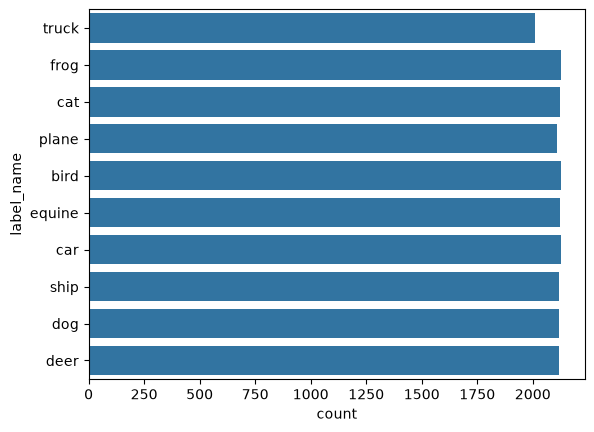

In [3]:
g = sns.countplot(Y_train)

Y_train.value_counts()

In [4]:
def read_image(path) :
  return np.array(Image.open(PATH+"/"+path).convert("RGB"))


In [5]:
(X_train == "").any()
#check no test has null

np.False_

In [6]:
print(read_image(X_train[0]).shape)
print(read_image(X_train[0]).max())
print(read_image(X_train[0]).min())

(224, 224, 3)
255
0


# Prepare Data for pytorch

In [7]:
#Prepare Data
X_train = X_train.apply(read_image)
X_test = X_test.apply(read_image)

In [8]:
encodings={
    "truck":0,
    "frog":1,
    "cat":2,
    "plane":3,
    "bird":4,
    "car":5,
    "equine":6,
    "ship":7,
    "deer":8,
    "dog":9,
}

reverse_encodings = {v: k for k, v in encodings.items()}

Y_train = Y_train.replace(encodings)

In [9]:
train_augmentations = v2.Compose([
    v2.RandomResizedCrop(224, scale=(0.4, 1.0), ratio=(3/4, 4/3), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
])


class ImageDataset(Dataset):
    def __init__(self, images, labels=None, augmentations=None):
        self.images = list(images)   # works for a list, an array or a pandas Series
        self.labels = labels
        self.augmentations = augmentations

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        x = torch.from_numpy(np.asarray(self.images[i])).permute(2, 0, 1)
        if self.augmentations is not None:
            x = self.augmentations(x)
        if self.labels is None:
            return x
        return x, self.labels[i]

Y_train = torch.from_numpy(Y_train.astype("int64").to_numpy())

rng = np.random.default_rng(666)
val_idx = []
VAL_PROPORTION = 0.1
for c in range(10):
    idx_c = np.where(Y_train.numpy() == c)[0]
    idx_c = rng.permutation(idx_c)
    n_val = int(VAL_PROPORTION*len(idx_c))
    val_idx.extend(idx_c[:n_val])
val_idx = np.array(val_idx)
train_idx = np.setdiff1d(np.arange(len(Y_train)), val_idx)


train_id = ImageDataset([X_train[i] for i in train_idx], Y_train[train_idx], augmentations=train_augmentations)
val_id   = ImageDataset([X_train[i] for i in val_idx], Y_train[val_idx])
test_id  = ImageDataset(X_test)

train_loader = DataLoader(train_id, batch_size=64, shuffle=True, persistent_workers=True, num_workers=4, pin_memory=True, multiprocessing_context="fork")
val_loader = DataLoader(val_id, batch_size=64, shuffle=False,                         num_workers=4, pin_memory=True, multiprocessing_context="fork")
test_loader = DataLoader(test_id, batch_size=64, shuffle=False,                        num_workers=4, pin_memory=True, multiprocessing_context="fork")

/tmp/ipykernel_201177/1672319347.py:25: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  Y_train = torch.from_numpy(Y_train.astype("int64").to_numpy())


# Define Model

In [10]:
def convolutionBlock_3x3(c_in, c_out):
  return nn.Sequential(
    nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
    nn.BatchNorm2d(c_out),
    nn.ReLU(inplace=True), 
    nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
    nn.BatchNorm2d(c_out),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(2),
  )

class CNN(nn.Module) :
  def __init__(self) :
    super().__init__()
    self.convolutions = nn.Sequential(
      convolutionBlock_3x3(3, 32),
      convolutionBlock_3x3(32, 64),
      convolutionBlock_3x3(64, 128),
      convolutionBlock_3x3(128, 256),
      convolutionBlock_3x3(256, 256),
    )

    self.classification = nn.Sequential(
      nn.AdaptiveAvgPool2d(1),
      nn.Flatten(),
      nn.Dropout(0.33),
      nn.Linear(256, 10),
    )


  def forward(self, x) :
    return self.classification(self.convolutions(x))


In [11]:
device="cuda"
model = CNN().to(device)

In [12]:
def create(epochs, max_lr=3e-3):
    model = CNN().to(device)
    opt = torch.optim.AdamW(model.parameters(), weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=max_lr, epochs=epochs, steps_per_epoch=len(train_loader))
    return model, opt, sched, 0.0

def load(path, epochs, max_lr=1e-3, resume_schedule=False):
    model, opt, sched, _ = create(epochs, max_lr)
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model"])
    if "optimizer" in ckpt:
        opt.load_state_dict(ckpt["optimizer"])
    if resume_schedule and "scheduler" in ckpt:
        sched.load_state_dict(ckpt["scheduler"])
    return model, opt, sched, ckpt["val_acc"]

EPOCHS = 40
model, opt, sched, best_accuracy = create(EPOCHS)
# EPOCHS = 10
# model, opt, sched, best_accuracy = load("../5ff4bc3.pt", EPOCHS)

# Train Model

In [13]:
loss_fn = nn.CrossEntropyLoss()
best_accuracy = 0
for epoch in range(EPOCHS):
    print(f"Epoch {epoch}")

    #training
    model.train()
    running_loss = 0
    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True).float() / 255
        yb = yb.to(device, non_blocking = True)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            loss = loss_fn(model(xb), yb)   
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        running_loss += loss.item()
    print(f"Loss: {running_loss/len(train_loader)}")

    #validation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True).float() / 255
            yb = yb.to(device, non_blocking=True)
            correct += (model(xb).argmax(dim=1) == yb).sum().item()
            total += len(yb)
    val_accurracy = correct / total
    print(f"Validation accuracy: {val_accurracy}")


    if val_accurracy > best_accuracy:
        best_accuracy = val_accurracy
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_acc": val_accurracy, "scheduler": sched.state_dict(), "optimizer": opt.state_dict()}, "../outputs/weights/cnn_hector.pt")
        
print(f"Best validation accuracy {best_accuracy}")

Epoch 0
Loss: 1.5527954667505592
Validation accuracy: 0.5083135391923991
Epoch 1
Loss: 1.1683901516275375
Validation accuracy: 0.607125890736342
Epoch 2
Loss: 0.9889459505627051
Validation accuracy: 0.6270783847980997
Epoch 3
Loss: 0.8680426382055186
Validation accuracy: 0.563895486935867
Epoch 4
Loss: 0.8013759080809776
Validation accuracy: 0.5111638954869359
Epoch 5
Loss: 0.7398939112621525
Validation accuracy: 0.6707838479809977
Epoch 6
Loss: 0.6826350027663941
Validation accuracy: 0.6232779097387173
Epoch 7
Loss: 0.6255294296275887
Validation accuracy: 0.6807600950118765
Epoch 8
Loss: 0.5718683468974399
Validation accuracy: 0.6199524940617577
Epoch 9
Loss: 0.5384371474335089
Validation accuracy: 0.7448931116389549
Epoch 10
Loss: 0.5128658014515834
Validation accuracy: 0.6532066508313539
Epoch 11
Loss: 0.47750822617750777
Validation accuracy: 0.7833729216152019
Epoch 12
Loss: 0.4300241331861477
Validation accuracy: 0.7501187648456057
Epoch 13
Loss: 0.4001390932485311
Validation accu

# Evaluate Model

In [14]:
model.load_state_dict(torch.load("../outputs/weights/cnn_hector.pt")["model"])
model.eval()
preds = []
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    for xb in test_loader:
        xb = xb.to(device, non_blocking=True).float() / 255
        preds.append(model(xb.to(device)).argmax(dim=1).cpu())
predictions = torch.cat(preds)

In [15]:
df = pd.DataFrame({
    "id": range(len(predictions)),
    "label": pd.Series(predictions.numpy()).map(reverse_encodings),
})
df.to_csv("../outputs/submissions/cnn_hector.csv", index=False)